In [1]:
import pandas as pd
import numpy as np

In [4]:
csv='../01.data/raw/ATOM_USD_ML_features.csv'
df = pd.read_csv(csv, parse_dates=["date"])
df.head(3)

,date,symbol,last_price,open,high,low,volume,last_return,return_3d,returnvola_3d,...,rsi_14,bb_upper_20,bb_lower_20,bb_width_20,high_low_range_pct,day_of_week,month,Surge,target_next_close,target_next_return
0,2020-01-26,ATOM/USD,4.480,4.379,4.505,4.363,355850.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.032427,6,1,0,4.515,0.007812
1,2020-01-27,ATOM/USD,4.515,4.474,4.672,4.401,1080000.0,0.007812,NaN,NaN,...,NaN,NaN,NaN,NaN,0.060572,0,1,1,4.601,0.019048
2,2020-01-28,ATOM/USD,4.601,4.516,4.609,4.473,577350.0,0.019048,NaN,NaN,...,NaN,NaN,NaN,NaN,0.030115,1,1,1,4.401,-0.043469


In [ ]:
print(df["date"].min().date(), "->", df["date"].max().date())

2020-01-26 -> 2026-09-26


In [5]:
print(df.nunique().sort_values().head(5))

symbol           1
Surge            2
day_of_week      7
month           12
volume         912
dtype: int64


In [3]:
df_features = df.columns
df_features

Index(['date', 'symbol', 'last_price', 'open', 'high', 'low', 'volume',
       'last_return', 'return_3d', 'returnvola_3d', 'volume_3d',
       'volumevola_3d', 'return_7d', 'returnvola_7d', 'volume_7d',
       'volumevola_7d', 'return_14d', 'returnvola_14d', 'volume_14d',
       'volumevola_14d', 'return_21d', 'returnvola_21d', 'volume_21d',
       'volumevola_21d', 'return_30d', 'returnvola_30d', 'volume_30d',
       'volumevola_30d', 'return_60d', 'returnvola_60d', 'volume_60d',
       'volumevola_60d', 'return_90d', 'returnvola_90d', 'volume_90d',
       'volumevola_90d', 'sma_7', 'sma_14', 'sma_30', 'sma_50', 'sma_90',
       'sma_200', 'ema_12', 'ema_26', 'macd', 'macd_signal', 'rsi_14',
       'bb_upper_20', 'bb_lower_20', 'bb_width_20', 'high_low_range_pct',
       'day_of_week', 'month', 'Surge', 'target_next_close',
       'target_next_return'],
      dtype='str')

In [4]:
df.dtypes

date                      str
symbol                    str
last_price            float64
open                  float64
high                  float64
low                   float64
volume                float64
last_return           float64
return_3d             float64
returnvola_3d         float64
volume_3d             float64
volumevola_3d         float64
return_7d             float64
returnvola_7d         float64
volume_7d             float64
volumevola_7d         float64
return_14d            float64
returnvola_14d        float64
volume_14d            float64
volumevola_14d        float64
return_21d            float64
returnvola_21d        float64
volume_21d            float64
volumevola_21d        float64
return_30d            float64
returnvola_30d        float64
volume_30d            float64
volumevola_30d        float64
return_60d            float64
returnvola_60d        float64
volume_60d            float64
volumevola_60d        float64
return_90d            float64
returnvola

i note everything is float 

In [5]:
df.head(1)

,date,symbol,last_price,open,high,low,volume,last_return,return_3d,returnvola_3d,...,rsi_14,bb_upper_20,bb_lower_20,bb_width_20,high_low_range_pct,day_of_week,month,Surge,target_next_close,target_next_return
0,2020-01-26,ATOM/USD,4.48,4.379,4.505,4.363,355850.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.032427,6,1,0,4.515,0.007812


In [6]:
df['date'] = pd.to_datetime(df['date'])

In [7]:
print(df['date'].dtypes)

datetime64[us]


In [8]:
# Convert the date column to a real datetime value for chronological sorting
df['date'] = pd.to_datetime(df['date'])

In [9]:
df.head(1)

,date,symbol,last_price,open,high,low,volume,last_return,return_3d,returnvola_3d,...,rsi_14,bb_upper_20,bb_lower_20,bb_width_20,high_low_range_pct,day_of_week,month,Surge,target_next_close,target_next_return
0,2020-01-26,ATOM/USD,4.48,4.379,4.505,4.363,355850.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.032427,6,1,0,4.515,0.007812


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2436 entries, 0 to 2435
Data columns (total 56 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   date                2436 non-null   datetime64[us]
 1   symbol              2436 non-null   str           
 2   last_price          2436 non-null   float64       
 3   open                2436 non-null   float64       
 4   high                2436 non-null   float64       
 5   low                 2436 non-null   float64       
 6   volume              2436 non-null   float64       
 7   last_return         2435 non-null   float64       
 8   return_3d           2433 non-null   float64       
 9   returnvola_3d       2433 non-null   float64       
 10  volume_3d           2434 non-null   float64       
 11  volumevola_3d       2434 non-null   float64       
 12  return_7d           2429 non-null   float64       
 13  returnvola_7d       2429 non-null   float64       
 14  vol

In [11]:
#check duplicate rows
df.duplicated().sum()

np.int64(0)

In [12]:
df.head()

,date,symbol,last_price,open,high,low,volume,last_return,return_3d,returnvola_3d,...,rsi_14,bb_upper_20,bb_lower_20,bb_width_20,high_low_range_pct,day_of_week,month,Surge,target_next_close,target_next_return
0,2020-01-26,ATOM/USD,4.480,4.379,4.505,4.363,355850.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.032427,6,1,0,4.515,0.007812
1,2020-01-27,ATOM/USD,4.515,4.474,4.672,4.401,1080000.0,0.007812,NaN,NaN,...,NaN,NaN,NaN,NaN,0.060572,0,1,1,4.601,0.019048
2,2020-01-28,ATOM/USD,4.601,4.516,4.609,4.473,577350.0,0.019048,NaN,NaN,...,NaN,NaN,NaN,NaN,0.030115,1,1,1,4.401,-0.043469
3,2020-01-29,ATOM/USD,4.401,4.577,4.597,4.355,1070000.0,-0.043469,-0.017634,0.033327,...,NaN,NaN,NaN,NaN,0.052873,2,1,0,4.410,0.002045
4,2020-01-30,ATOM/USD,4.410,4.399,4.480,4.307,903250.0,0.002045,-0.023256,0.032324,...,NaN,NaN,NaN,NaN,0.039327,3,1,0,4.397,-0.002948


In [13]:
#checking for date sorted or not
df['date'].is_monotonic_increasing

True

In [14]:
# Sort the complete dataset chronologically, then rebuild the row index
df.sort_values(by='date', ascending=True, inplace=True)
df.reset_index(drop=True, inplace=True)

In [15]:
df['date'].is_monotonic_increasing

True

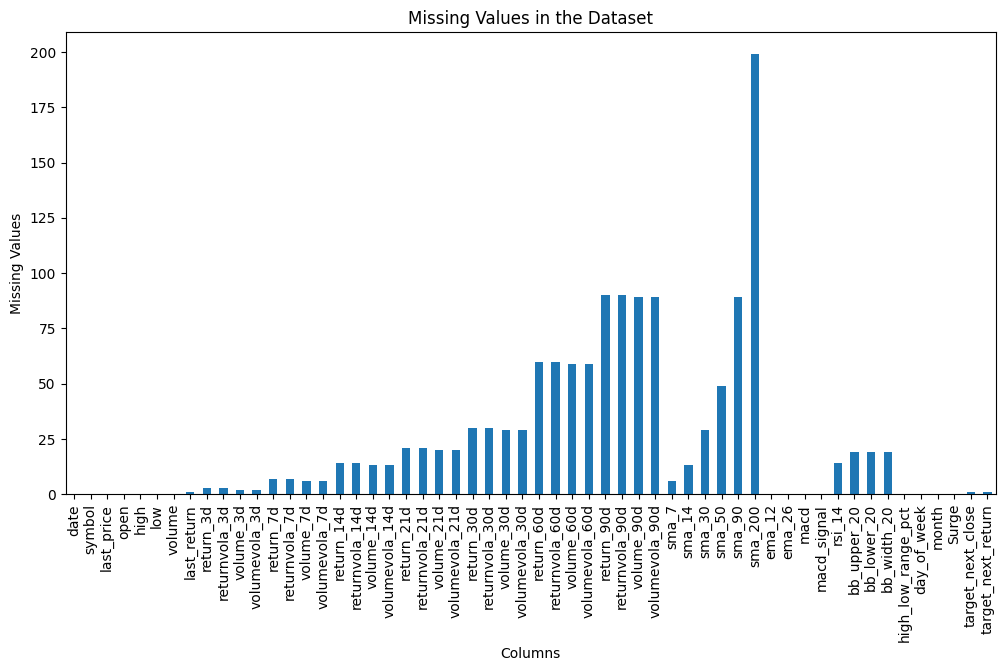

In [16]:
from pathlib import Path

#visualizing the missing values in the dataset
import matplotlib.pyplot as plt
df.isnull().sum().plot(kind='bar', figsize=(12, 6), title='Missing Values in the Dataset')
plt.xlabel('Columns')
plt.ylabel('Missing Values')
output_path = Path('../03.results/eda_visualizations/missing_values.png')
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, dpi=120, bbox_inches='tight')
plt.show()

In [17]:
#handling null values in the dataset
df.isnull().sum()

date                    0
symbol                  0
last_price              0
open                    0
high                    0
low                     0
volume                  0
last_return             1
return_3d               3
returnvola_3d           3
volume_3d               2
volumevola_3d           2
return_7d               7
returnvola_7d           7
volume_7d               6
volumevola_7d           6
return_14d             14
returnvola_14d         14
volume_14d             13
volumevola_14d         13
return_21d             21
returnvola_21d         21
volume_21d             20
volumevola_21d         20
return_30d             30
returnvola_30d         30
volume_30d             29
volumevola_30d         29
return_60d             60
returnvola_60d         60
volume_60d             59
volumevola_60d         59
return_90d             90
returnvola_90d         90
volume_90d             89
volumevola_90d         89
sma_7                   6
sma_14                 13
sma_30      

In [18]:
#removing row atget has null values in the dataset
from numpy import mean
df['target_next_close'] = df['target_next_close'].replace(np.nan, mean(df['target_next_close']))
df['target_next_return'] = df['target_next_return'].replace(np.nan, mean(df['target_next_return']))

In [19]:
df.isna().sum()

date                    0
symbol                  0
last_price              0
open                    0
high                    0
low                     0
volume                  0
last_return             1
return_3d               3
returnvola_3d           3
volume_3d               2
volumevola_3d           2
return_7d               7
returnvola_7d           7
volume_7d               6
volumevola_7d           6
return_14d             14
returnvola_14d         14
volume_14d             13
volumevola_14d         13
return_21d             21
returnvola_21d         21
volume_21d             20
volumevola_21d         20
return_30d             30
returnvola_30d         30
volume_30d             29
volumevola_30d         29
return_60d             60
returnvola_60d         60
volume_60d             59
volumevola_60d         59
return_90d             90
returnvola_90d         90
volume_90d             89
volumevola_90d         89
sma_7                   6
sma_14                 13
sma_30      

In [20]:
# missing data handling
df['last_return']= df['last_return'].replace(np.nan, mean(df['last_return']))
df['return_3d']= df['return_3d'].replace(np.nan, mean(df['return_3d']))
df['volumevola_3d']= df['volumevola_3d'].replace(np.nan, mean(df['volumevola_3d']))
df['returnvola_3d']= df['returnvola_3d'].replace(np.nan, mean(df['returnvola_3d']))
df['volume_3d']= df['volume_3d'].replace(np.nan, mean(df['volume_3d']))
df['volumevola_3d']= df['volumevola_3d'].replace(np.nan, mean(df['volumevola_3d']))
df['return_7d']= df['return_7d'].replace(np.nan, mean(df['return_7d']))
df['volumevola_7d']= df['volumevola_7d'].replace(np.nan, mean(df['volumevola_7d']))
df['returnvola_7d']= df['returnvola_7d'].replace(np.nan, mean(df['returnvola_7d']))
df['volume_7d']= df['volume_7d'].replace(np.nan, mean(df['volume_7d']))
df['return_14d']= df['return_14d'].replace(np.nan, mean(df['return_14d']))
df['returnvola_14d']= df['returnvola_14d'].replace(np.nan, mean(df['returnvola_14d']))
df['volume_14d']= df['volume_14d'].replace(np.nan, mean(df['volume_14d']))
df['volumevola_14d']= df['volumevola_14d'].replace(np.nan, mean(df['volumevola_14d']))
df['return_21d']= df['return_21d'].replace(np.nan, mean(df['return_21d']))
df['returnvola_21d']= df['returnvola_21d'].replace(np.nan, mean(df['returnvola_21d']))
df['volume_21d']= df['volume_21d'].replace(np.nan, mean(df['volume_21d']))
df['volumevola_21d']= df['volumevola_21d'].replace(np.nan, mean(df['volumevola_21d']))
df['return_30d']= df['return_30d'].replace(np.nan, mean(df['return_30d']))
df['returnvola_30d']= df['returnvola_30d'].replace(np.nan, mean(df['returnvola_30d']))
df['volume_30d']= df['volume_30d'].replace(np.nan, mean(df['volume_30d']))
df['volumevola_30d']= df['volumevola_30d'].replace(np.nan, mean(df['volumevola_30d']))
df['return_60d']= df['return_60d'].replace(np.nan, mean(df['return_60d']))
df['volume_60d']= df['volume_60d'].replace(np.nan, mean(df['volume_60d']))
df['volumevola_60d']= df['volumevola_60d'].replace(np.nan, mean(df['volumevola_60d']))
df['return_90d']= df['return_90d'].replace(np.nan, mean(df['return_90d']))
df['returnvola_90d']= df['returnvola_90d'].replace(np.nan, mean(df['returnvola_90d']))

In [21]:
df.isna().sum()

date                    0
symbol                  0
last_price              0
open                    0
high                    0
low                     0
volume                  0
last_return             0
return_3d               0
returnvola_3d           0
volume_3d               0
volumevola_3d           0
return_7d               0
returnvola_7d           0
volume_7d               0
volumevola_7d           0
return_14d              0
returnvola_14d          0
volume_14d              0
volumevola_14d          0
return_21d              0
returnvola_21d          0
volume_21d              0
volumevola_21d          0
return_30d              0
returnvola_30d          0
volume_30d              0
volumevola_30d          0
return_60d              0
returnvola_60d         60
volume_60d              0
volumevola_60d          0
return_90d              0
returnvola_90d          0
volume_90d             89
volumevola_90d         89
sma_7                   6
sma_14                 13
sma_30      

In [22]:
#missing data handling
df['volume_90d']= df['volume_90d'].replace(np.nan, mean(df['volume_90d']))
df['volumevola_90d']= df['volumevola_90d'].replace(np.nan, mean(df['volumevola_90d']))
df['sma_7']= df['sma_7'].replace(np.nan, mean(df['sma_7']))
df['sma_14']= df['sma_14'].replace(np.nan, mean(df['sma_14']))
df['sma_30']= df['sma_30'].replace(np.nan, mean(df['sma_30']))
df['sma_50']= df['sma_50'].replace(np.nan, mean(df['sma_50']))
df['sma_90']= df['sma_90'].replace(np.nan, mean(df['sma_90']))
df['sma_200']= df['sma_200'].replace(np.nan, mean(df['sma_200']))
df['rsi_14']= df['rsi_14'].replace(np.nan, mean(df['rsi_14']))
df['bb_upper_20']= df['bb_upper_20'].replace(np.nan, mean(df['bb_upper_20']))
df['bb_lower_20']= df['bb_lower_20'].replace(np.nan, mean(df['bb_lower_20']))
df['bb_width_20']= df['bb_width_20'].replace(np.nan, mean(df['bb_width_20']))

In [23]:
df.isna().sum()

date                   0
symbol                 0
last_price             0
open                   0
high                   0
low                    0
volume                 0
last_return            0
return_3d              0
returnvola_3d          0
volume_3d              0
volumevola_3d          0
return_7d              0
returnvola_7d          0
volume_7d              0
volumevola_7d          0
return_14d             0
returnvola_14d         0
volume_14d             0
volumevola_14d         0
return_21d             0
returnvola_21d         0
volume_21d             0
volumevola_21d         0
return_30d             0
returnvola_30d         0
volume_30d             0
volumevola_30d         0
return_60d             0
returnvola_60d        60
volume_60d             0
volumevola_60d         0
return_90d             0
returnvola_90d         0
volume_90d             0
volumevola_90d         0
sma_7                  0
sma_14                 0
sma_30                 0
sma_50                 0


i don't scale the  data bcz i will use random forest algorithm

In [24]:
# saving the preprocessed data to a new CSV file
df.to_csv('../03.results/outputs/ATOM_USD_ML_features_preprocessed.csv', index=False)